In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate, GridSearchCV
from sklearn.dummy import DummyRegressor 
from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.pipeline import make_pipeline 
from sklearn.preprocessing import StandardScaler, PolynomialFeatures 
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score 
df = pd.read_csv("lab_ticket_resolution.csv") 

print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nDescriptive statistics:")
print(df.describe(include="all"))

print("\nMissing values:")
print(df.isna().sum())

print("\nFirst five rows:")
print(df.head())


# TASK 2
y = df["resolution_hours"]


X = df[
    [
        "complexity_score",
        "team_experience_years",
    ]
]

print("\nX shape:", X.shape)
print("y shape:", y.shape)

print("\nInput features:")
print(X.head())

print("\nTarget values:")
print(y.head())




Shape: (240, 6)

Data types:
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Descriptive statistics:
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000 

The features that are available during the intended prediction time are complexity score and team experience years. As for why we exluded the others, an explanation is given below:
- Ticket ID: It is an identifier and not a meaningful feature.
- Lines Changed: Since this information is generally known after the work is done , there is a risk of leakage.
- Reopened: Whether a ticket was reopened is knwon only after the initial resolution so it was exluded.

In [2]:
#TASK 3
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\n", y_train.describe())

X_train: (192, 2)
X_test: (48, 2)
y_train: (192,)
y_test: (48,)

 count    192.000000
mean      19.057031
std        9.894506
min        0.500000
25%       10.905000
50%       18.605000
75%       26.620000
max       41.420000
Name: resolution_hours, dtype: float64


In [3]:
#TASK 4

dummy_regressor = DummyRegressor(strategy="mean")
dummy_regressor.fit(X_train, y_train)

y_pred_dummy = dummy_regressor.predict(X_test)

dummy_mae = mean_absolute_error(y_test, y_pred_dummy)
dummy_rmse = np.sqrt(mean_squared_error(y_test, y_pred_dummy))
dummy_r2 = r2_score(y_test, y_pred_dummy)

print("\nDummy Regression Results")
print(f"MAE:  {dummy_mae:.4f} hours")
print(f"RMSE: {dummy_rmse:.4f} hours")
print(f"R²:   {dummy_r2:.4f}")


Dummy Regression Results
MAE:  9.1140 hours
RMSE: 10.5977 hours
R²:   -0.0210


In [4]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, y_pred_linear)
linear_rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))
linear_r2 = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print(f"MAE:  {linear_mae:.4f} hours")
print(f"RMSE: {linear_rmse:.4f} hours")
print(f"R²:   {linear_r2:.4f}")

Linear Regression Results
MAE:  2.9060 hours
RMSE: 3.5723 hours
R²:   0.8840


In [5]:
poly2_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly2_model.fit(X_train, y_train)

y_pred_poly2 = poly2_model.predict(X_test)

poly2_mae = mean_absolute_error(y_test, y_pred_poly2)
poly2_rmse = np.sqrt(mean_squared_error(y_test, y_pred_poly2))
poly2_r2 = r2_score(y_test, y_pred_poly2)

print("Polynomial Regression (Degree 2) Results")
print(f"MAE:  {poly2_mae:.4f} hours")
print(f"RMSE: {poly2_rmse:.4f} hours")
print(f"R²:   {poly2_r2:.4f}")

Polynomial Regression (Degree 2) Results
MAE:  3.0202 hours
RMSE: 3.7409 hours
R²:   0.8728


In [6]:
poly3_model = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)

poly3_model.fit(X_train, y_train)

y_pred_poly3 = poly3_model.predict(X_test)

poly3_mae = mean_absolute_error(y_test, y_pred_poly3)
poly3_rmse = np.sqrt(mean_squared_error(y_test, y_pred_poly3))
poly3_r2 = r2_score(y_test, y_pred_poly3)

print("Polynomial Regression (Degree 3) Results")
print(f"MAE:  {poly3_mae:.4f} hours")
print(f"RMSE: {poly3_rmse:.4f} hours")
print(f"R²:   {poly3_r2:.4f}")

Polynomial Regression (Degree 3) Results
MAE:  3.1398 hours
RMSE: 3.9489 hours
R²:   0.8582


In [7]:
results = pd.DataFrame({
    "Model": [
        "Dummy Regression",
        "Linear Regression",
        "Polynomial Regression (Degree 2)",
        "Polynomial Regression (Degree 3)"
    ],
    "MAE": [dummy_mae, linear_mae, poly2_mae, poly3_mae],
    "RMSE": [dummy_rmse, linear_rmse, poly2_rmse, poly3_rmse],
    "R²": [dummy_r2, linear_r2, poly2_r2, poly3_r2]
})

print(results.round(4).to_string(index=False))

                           Model    MAE    RMSE      R²
                Dummy Regression 9.1140 10.5977 -0.0210
               Linear Regression 2.9060  3.5723  0.8840
Polynomial Regression (Degree 2) 3.0202  3.7409  0.8728
Polynomial Regression (Degree 3) 3.1398  3.9489  0.8582


In [8]:
# TASK 6
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        LinearRegression()
    ),
    "Polynomial Degree 2": make_pipeline(
        PolynomialFeatures(degree=2, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ),
    "Polynomial Degree 3": make_pipeline(
        PolynomialFeatures(degree=3, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )
}

results_cv = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2"
        }
    )

    mae = -scores["test_mae"].mean()
    rmse = np.sqrt(-scores["test_mse"].mean())
    r2 = scores["test_r2"].mean()

    results_cv.append({
        "Model": name,
        "CV MAE": mae,
        "CV RMSE": rmse,
        "CV R²": r2
    })

cv_table = pd.DataFrame(results_cv)
print(cv_table.round(4).to_string(index=False))

              Model  CV MAE  CV RMSE  CV R²
  Linear Regression  3.1682   3.9308 0.8382
Polynomial Degree 2  3.1313   3.8602 0.8437
Polynomial Degree 3  3.1620   3.8893 0.8407


Polynomial features of degree 2 produced a small improvement in cross-validation performance compared with linear regression. Degree 3 did not improve upon degree 2. However, the linear regression model achieved the best results on the held-out test set. This suggests that the benefit of additional polynomial complexity is limited, and the final model should be chosen based on validation results and confirmed by test-set performance.

In [9]:
#TASK 7

cv = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_pipeline = make_pipeline(
    StandardScaler(),
    Ridge()
)

param_grid = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv
)

ridge_search.fit(X_train, y_train)

print("Best alpha:", ridge_search.best_params_["ridge__alpha"])
print("Best cross-validation MAE:", -ridge_search.best_score_)

Best alpha: 0.01
Best cross-validation MAE: 3.168179510394688


In [10]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

lasso_pipeline = make_pipeline(
    StandardScaler(),
    Lasso(max_iter=10000)
)

param_grid = {
    "lasso__alpha": [0.001, 0.01, 0.1, 1, 10, 100]
}

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=param_grid,
    scoring="neg_mean_absolute_error",
    cv=cv
)

lasso_search.fit(X_train, y_train)

print("Best alpha:", lasso_search.best_params_["lasso__alpha"])
print("Best cross-validation MAE:", -lasso_search.best_score_)

Best alpha: 0.001
Best cross-validation MAE: 3.1682419077442643


In [11]:
selected_models = {
    "Linear Regression": make_pipeline(
        StandardScaler(),
        __import__("sklearn.linear_model", fromlist=["LinearRegression"]).LinearRegression()
    ),
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_
}

test_results = []

for name, model in selected_models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    test_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R²": r2_score(y_test, predictions)
    })

test_table = pd.DataFrame(test_results)
print(test_table.round(4).to_string(index=False))

            Model    MAE   RMSE    R²
Linear Regression 2.9060 3.5723 0.884
            Ridge 2.9060 3.5723 0.884
            Lasso 2.9061 3.5723 0.884


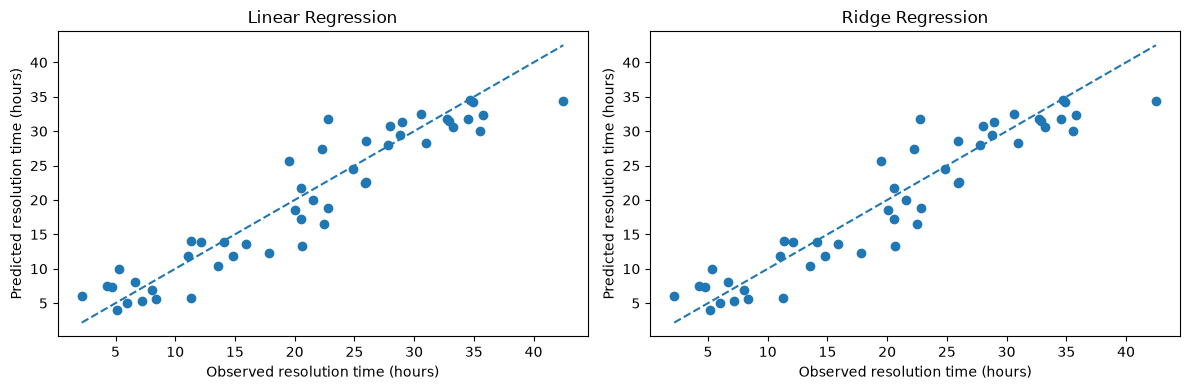

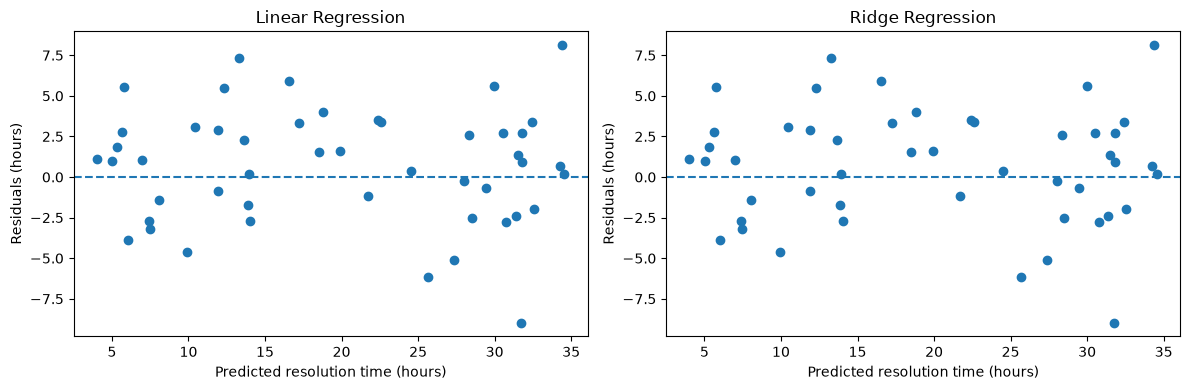

In [12]:

linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

ridge_model = ridge_search.best_estimator_

linear_model.fit(X_train, y_train)
ridge_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)
ridge_predictions = ridge_model.predict(X_test)

# Plot 1: Observed vs. predicted values
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name, predictions in [
    (axes[0], "Linear Regression", linear_predictions),
    (axes[1], "Ridge Regression", ridge_predictions)
]:
    ax.scatter(y_test, predictions)
    ax.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        linestyle="--"
    )
    ax.set_xlabel("Observed resolution time (hours)")
    ax.set_ylabel("Predicted resolution time (hours)")
    ax.set_title(name)

plt.tight_layout()
plt.show()

# Plot 2: Residuals vs. predicted values
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, name, predictions in [
    (axes[0], "Linear Regression", linear_predictions),
    (axes[1], "Ridge Regression", ridge_predictions)
]:
    residuals = y_test - predictions
    ax.scatter(predictions, residuals)
    ax.axhline(y=0, linestyle="--")
    ax.set_xlabel("Predicted resolution time (hours)")
    ax.set_ylabel("Residuals (hours)")
    ax.set_title(name)

plt.tight_layout()
plt.show()

The observed-versus-predicted plots show that both Linear Regression and Ridge Regression produce predictions that are generally close to the ideal diagonal line. This indicates that both models capture the relationship between the selected features and ticket resolution time reasonably well.

The residual plots show residuals distributed on both sides of the zero line, with no obvious strong curved pattern. However, some tickets have relatively large residuals, indicating that the models sometimes substantially underestimate or overestimate resolution time.

The two models produce nearly identical plots, consistent with their test-set results: MAE of approximately 2.906 hours, RMSE of 3.572 hours, and (R^2) of 0.884. Therefore, Ridge regularization provides no meaningful improvement over ordinary Linear Regression for this dataset under the selected settings.

Based on the results, I recommend Linear Regression as the final model:
- It performs better than the mean-prediction baseline.
- It achieves a test MAE of approximately 2.91 hours and an R^2 of 0.884.
- Ridge and Lasso provide no meaningful improvement on the test set.
- Polynomial Degree 2 performed slightly better during cross-validation, but Linear Regression performed better on the held-out test set.

**Analysis Questions**
10. Why is the mean baseline useful even though it ignores all features?
The mean baseline provides a simple reference point for evaluating more advanced models. It predicts the average resolution time calculated from the training set for every ticket, without considering any features.

Although it does not account for differences between tickets, it helps determine whether a model actually learns useful patterns. In this experiment, the baseline achieved a test MAE of 9.1140 hours and RMSE of 10.5977 hours, while Linear Regression achieved a MAE of 2.9060 hours and RMSE of 3.5723 hours. This demonstrates that Linear Regression performs substantially better than simply predicting the mean.
11. Which model has the lowest MAE? Which has the lowest RMSE? Are they the same, and why might they differ?
Linear Regression achieved the lowest test MAE of 2.9060 hours. Ridge achieved the same MAE to four decimal places, while Lasso had a slightly higher MAE of 2.9061 hours.

Linear Regression, Ridge, and Lasso also achieved the same lowest RMSE of 3.5723 hours to four decimal places.

MAE measures the average absolute prediction error, whereas RMSE squares errors before averaging and then takes the square root. Therefore, RMSE penalizes large errors more heavily than MAE. The metrics can favor different models because a model may have smaller errors on average but make a few larger mistakes. In this experiment, the reported results are essentially identical for the three models.
12. Did polynomial features improve validation performance? What is the evidence of possible overfitting?
Yes, Polynomial Regression with degree 2 slightly improved cross-validation performance compared with ordinary Linear Regression.
Model	CV MAE	CV RMSE	CV R²
Linear Regression	3.1682	3.9308	0.8382
Polynomial Degree 2	3.1313	3.8602	0.8437
Polynomial Degree 3	3.1620	3.8893	0.8407

Degree 2 achieved the best cross-validation results across all three metrics, although the improvement was small. Degree 3 performed worse than degree 2 during cross-validation.

On the held-out test set, however, ordinary Linear Regression outperformed both polynomial models. This suggests that the additional polynomial complexity did not improve generalization on that test set and could indicate some overfitting or sensitivity to the particular data split. However, these results alone do not prove overfitting.
13. How did regularization affect performance and coefficient magnitudes?
Ridge and Lasso produced almost identical test performance to ordinary Linear Regression. Ridge achieved a test MAE of 2.9060 hours, RMSE of 3.5723 hours, and R² of 0.884. Lasso produced nearly the same results.

Regularization penalizes large coefficients to reduce model complexity. Ridge shrinks coefficients toward zero, while Lasso can shrink some coefficients completely to zero, effectively removing their contribution to the model.

The selected alpha values were 0.01 for Ridge and 0.001 for Lasso. These small penalties are consistent with the negligible performance differences observed. To determine exactly how much the coefficients changed, we would need to inspect the fitted coefficients directly.
14. Why is scaling included in the Ridge/Lasso pipeline?
Scaling places features on comparable numerical scales. For example, team experience is measured in years, while complexity is measured on a 1–10 scale.

Ridge and Lasso penalize coefficient magnitudes. Without scaling, features with different numerical ranges could be penalized unfairly because their coefficient sizes would not be directly comparable.

Including StandardScaler in the pipeline helps ensure that regularization is applied more fairly across features. It also prevents data leakage during cross-validation because the scaler is fitted separately on each training fold.
15. Identify one potential leakage issue in the dataset and explain how you handled it.
The lines_changed feature is a potential source of data leakage because it represents the number of code lines changed during the fix. When predicting resolution time at ticket submission, this information may not yet be available and could depend on work performed after the prediction point.

The reopened feature can also cause leakage because a ticket cannot be known to have been reopened until after a reopening event occurs.

I excluded both lines_changed and reopened from the predictive features, along with ticket_id, which is only an identifier. I used complexity_score and team_experience_years as features and resolution_hours as the target. This ensures that the model uses information intended to be available when the ticket is submitted.

16. Would a random split be appropriate if tickets were collected over several years or came from repeated customers/teams? Explain.
A random split might not be appropriate if tickets were collected over several years or if multiple tickets came from the same customers or teams.

When predicting future tickets, a random split could place older and newer tickets in both training and test sets. This may allow the model to benefit from patterns that would not be available when making genuinely future predictions.

Similarly, tickets from the same customer or team could appear in both sets, making the test results overly optimistic if those tickets share characteristics.

For time-dependent data, a chronological split would be more appropriate: train on earlier tickets and test on later tickets. If the goal is to generalize to unseen customers or teams, a group-based split should be considered so that the same group does not appear in both training and test sets.
17. What additional tests would you perform before deploying this model?
Before deployment, I would perform the following checks:
1. Validate on real-world data: The supplied dataset is synthetic, so the model should be evaluated on real support-ticket records.
2. Test on future tickets: Use a chronological holdout to evaluate performance on tickets received after the training period.
3. Investigate large errors: Examine tickets with unusually large residuals to understand why the model underestimates or overestimates their resolution times.
4. Check for data leakage: Confirm that every feature is available at the intended prediction time.
5. Evaluate different ticket groups: Compare errors across complexity levels, teams, and other relevant groups to identify weaknesses.
6. Monitor performance after deployment: Track prediction errors over time and retrain the model if ticket characteristics or team practices change.
7. Compare with operational requirements: Determine whether an average error of approximately 2.91 hours is acceptable for scheduling, workload planning, or communicating estimated resolution times.
Because the dataset is synthetic and contains only 240 tickets, these additional tests are necessary before concluding that the model will perform reliably in a real support environment.